# Late Mile: why Olist orders arrive late, and what it costs in reviews

**Question.** How often are Olist orders delivered late, where in the delivery chain does the delay come from, and what does lateness do to customer reviews?

**Data.** [Olist Brazilian E-Commerce Public Dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Kaggle, 2016-18). Not included in this repo (download it from Kaggle and put the files in `data/raw/`).

**Tools.** Python, DuckDB (SQL), pandas, matplotlib. The dashboard is in `dashboard/late_mile.pbip`.

**Definitions used throughout**
- *Delivered order*: status `delivered` with a customer delivery date.
- *Late*: delivered date is after the estimated (promised) date. `delay_days` counts calendar-day boundaries between the two dates, so same-day delivery is not late.
- *Stages*: `seller_days` = purchase to carrier pickup, `carrier_days` = carrier pickup to customer delivery.
- *GMV*: item value in R$ (excludes freight). It is sales value, not lost revenue.

**How this notebook is organised**
1. Setup
2. Part A (optional): rebuild `order_facts` from the raw Kaggle files
3. Part B: build the summary tables with SQL and check them against the saved CSVs
4. Part C: the findings, with every number from the dashboard recomputed
5. Limitations

## 1. Setup

In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # works from the repo root or from notebooks/
RAW = ROOT / "data" / "raw"              # the 9 original Kaggle CSVs (only needed for Part A)
PROCESSED = ROOT / "data" / "processed"  # order_facts.csv and the summary tables
REBUILT = ROOT / "data" / "rebuilt"      # tables written by this notebook
REBUILT.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
print("raw files found:", RAW.exists() and len(list(RAW.glob("*.csv"))) > 0)
print("processed files found:", sorted(p.name for p in PROCESSED.glob("*.csv")))

raw files found: False
processed files found: ['delay_bucket_summary.csv', 'delay_curve.csv', 'monthly_trend.csv', 'order_facts.csv', 'seller_summary.csv', 'state_review_gap.csv', 'state_summary.csv']


## 2. Part A (optional): rebuild `order_facts` from the raw Olist files

`order_facts` has one row per delivered order. This part needs the raw Kaggle files in `data/raw/`. If they are missing, the cell prints a message and Part B uses the saved `data/processed/order_facts.csv`.

**Choices made when building it**
- Orders with several reviews use the most recent review.
- `came_back` = the same customer has another delivered order placed at or after this one.
- Day counts use `date_diff('day', start, end)`, which counts calendar-day boundaries.

These rules reproduce the saved file's day counts, late flag, buckets, 1-star flag and order value with no exceptions. `came_back` is the closest rule I found (about 99.7% of rows match), so it is an approximation.

In [2]:
HAVE_RAW = RAW.exists() and (RAW / "olist_orders_dataset.csv").exists()

if HAVE_RAW:
    def raw(name):
        return f"read_csv_auto('{(RAW / name).as_posix()}')"

    con.execute(f"""
    create or replace table order_facts_rebuilt as
    with items as (
        select order_id,
               sum(price)                  as item_value,
               sum(freight_value)          as freight_value,
               count(*)                    as n_items,
               count(distinct seller_id)   as n_sellers
        from {raw('olist_order_items_dataset.csv')}
        group by 1
    ),
    reviews as (
        select order_id, review_score
        from (
            select order_id, review_score,
                   row_number() over (partition by order_id
                                      order by review_creation_date desc, review_answer_timestamp desc) as rn
            from {raw('olist_order_reviews_dataset.csv')}
        )
        where rn = 1
    ),
    base as (
        select o.order_id,
               c.customer_unique_id,
               c.customer_state,
               o.order_purchase_timestamp          as purchase_ts,
               o.order_delivered_carrier_date      as carrier_ts,
               o.order_delivered_customer_date     as delivered_ts,
               o.order_estimated_delivery_date     as estimated_ts,
               i.item_value, i.freight_value, i.n_items, i.n_sellers,
               r.review_score
        from {raw('olist_orders_dataset.csv')} o
        join {raw('olist_customers_dataset.csv')} c using (customer_id)
        join items i using (order_id)
        left join reviews r using (order_id)
        where o.order_status = 'delivered'
          and o.order_delivered_customer_date is not null
    ),
    calc as (
        select *,
               date_diff('day', estimated_ts, delivered_ts) as delay_days,
               date_diff('day', purchase_ts,  carrier_ts)   as seller_days,
               date_diff('day', carrier_ts,   delivered_ts) as carrier_days,
               date_diff('day', purchase_ts,  estimated_ts) as promised_days,
               date_diff('day', purchase_ts,  delivered_ts) as total_days,
               item_value + freight_value                   as order_value
        from base
    )
    select order_id, customer_unique_id, customer_state,
           purchase_ts, carrier_ts, delivered_ts, estimated_ts,
           delay_days, seller_days, carrier_days, promised_days, total_days,
           item_value, freight_value, order_value, n_items, n_sellers, review_score,
           case when delay_days <= 0  then '1. Early/on-time'
                when delay_days <= 2  then '2. 1-2 days late'
                when delay_days <= 5  then '3. 3-5 days late'
                when delay_days <= 10 then '4. 6-10 days late'
                else                       '5. 11+ days late' end as delay_bucket,
           (delay_days > 0)::int        as is_late,
           coalesce((review_score = 1)::int, 0) as is_one_star,   -- orders without a review count as 0
           (exists (select 1 from calc b
                    where b.customer_unique_id = calc.customer_unique_id
                      and b.order_id <> calc.order_id
                      and b.purchase_ts >= calc.purchase_ts))::int as came_back
    from calc
    """)
    n = con.execute("select count(*) from order_facts_rebuilt").fetchone()[0]
    con.execute(f"copy order_facts_rebuilt to '{(REBUILT / 'order_facts_rebuilt.csv').as_posix()}' (header, delimiter ',')")
    print(f"order_facts rebuilt from raw files: {n:,} delivered orders")
else:
    print("Raw files not found in data/raw/. Skipping Part A and using data/processed/order_facts.csv.")

Raw files not found in data/raw/. Skipping Part A and using data/processed/order_facts.csv.


In [3]:
# Check the rebuilt table against the saved order_facts.csv (only runs when both exist)
saved = PROCESSED / "order_facts.csv"
if HAVE_RAW and saved.exists():
    con.execute(f"create or replace view order_facts_saved as select * from read_csv_auto('{saved.as_posix()}')")
    print("rows   rebuilt vs saved:", con.execute("select count(*) from order_facts_rebuilt").fetchone()[0],
          con.execute("select count(*) from order_facts_saved").fetchone()[0])
    cols = ["delay_days", "seller_days", "carrier_days", "promised_days", "total_days",
            "review_score", "delay_bucket", "is_late", "is_one_star", "came_back"]
    for col in cols:
        diff = con.execute(f"""
            select count(*) from order_facts_rebuilt r join order_facts_saved s using (order_id)
            where r.{col} is distinct from s.{col}""").fetchone()[0]
        print(f"  {col:<14} differing rows: {diff}")
else:
    print("Nothing to compare (needs both the raw files and data/processed/order_facts.csv).")

Nothing to compare (needs both the raw files and data/processed/order_facts.csv).


## 3. Part B: summary tables in SQL

Everything below reads from `order_facts`. I load the saved `data/processed/order_facts.csv`, falling back to the rebuilt table if that file is missing. Each query builds one dashboard table, and each table is compared with the saved CSV from the original analysis.

In [4]:
if (PROCESSED / "order_facts.csv").exists():
    con.execute(f"create or replace view order_facts as select * from read_csv_auto('{(PROCESSED / 'order_facts.csv').as_posix()}')")
    source = "data/processed/order_facts.csv"
else:
    con.execute("create or replace view order_facts as select * from order_facts_rebuilt")
    source = "rebuilt from raw files"

print("order_facts source:", source)
con.execute("select count(*) as orders, sum(is_late) as late_orders, round(100 * avg(is_late), 2) as late_pct from order_facts").fetchdf()

order_facts source: data/processed/order_facts.csv


,orders,late_orders,late_pct
0,96470,6534.0,6.77


### 3.1 Delay buckets: reviews, 1-star share, repeat purchase and stage times

In [5]:
Q_BUCKET = """
select delay_bucket,
       count(*)                          as orders,
       round(avg(review_score), 2)       as avg_review,
       round(100 * avg(is_one_star), 1)  as pct_one_star,
       round(100 * avg(came_back), 1)    as pct_came_back,
       round(avg(order_value), 2)        as avg_order_value,
       round(avg(seller_days), 1)        as avg_seller_days,
       round(avg(carrier_days), 1)       as avg_carrier_days
from order_facts
group by 1
order by 1
"""
delay_bucket_summary = con.execute(Q_BUCKET).fetchdf()
delay_bucket_summary

,delay_bucket,orders,avg_review,pct_one_star,pct_came_back,avg_order_value,avg_seller_days,avg_carrier_days
0,1. Early/on-time,89936,4.29,6.6,3.3,158.64,3.0,7.9
1,2. 1-2 days late,1370,3.51,18.5,2.4,159.38,5.0,17.8
2,3. 3-5 days late,1400,2.47,47.2,2.4,174.30,5.6,20.2
3,4. 6-10 days late,1672,1.77,66.3,2.8,183.04,6.3,24.9
4,5. 11+ days late,2092,1.71,67.3,3.0,182.83,6.8,42.0


### 3.2 The tipping-point curve: average review by days late

In [6]:
Q_CURVE = """
select case when delay_days <= 0 then 0 else least(delay_days, 15) end as days_late,   -- 15 means 15+ days
       count(*)                          as orders,
       round(avg(review_score), 2)       as avg_review,
       round(100 * avg(is_one_star), 1)  as pct_one_star
from order_facts
group by 1
order by 1
"""
delay_curve = con.execute(Q_CURVE).fetchdf()
delay_curve

,days_late,orders,avg_review,pct_one_star
0,0,89936,4.29,6.6
1,1,825,3.73,13.0
2,2,545,3.18,27.0
3,3,500,2.68,42.2
4,4,453,2.50,46.4
5,5,447,2.20,53.7
6,6,419,1.81,66.6
7,7,483,1.91,61.1
8,8,336,1.71,67.6
9,9,227,1.67,69.6


### 3.3 Monthly trend (months with at least 100 orders)

In [7]:
Q_MONTH = """
select strftime(purchase_ts, '%Y-%m')    as "month",
       count(*)                          as orders,
       sum(is_late)                      as late_orders,
       round(100 * avg(is_late), 1)      as late_pct,
       round(avg(review_score), 2)       as avg_review,
       round(sum(item_value), 0)         as gmv
from order_facts
group by 1
having count(*) >= 100        -- drops two near-empty months (1 order each)
order by 1
"""
monthly_trend = con.execute(Q_MONTH).fetchdf()
monthly_trend

,month,orders,late_orders,late_pct,avg_review,gmv
0,2016-10,265,2.0,0.8,4.01,40325.0
1,2017-01,750,22.0,2.9,4.20,111798.0
2,2017-02,1653,49.0,3.0,4.20,234223.0
3,2017-03,2546,116.0,4.6,4.19,359199.0
4,2017-04,2303,151.0,6.6,4.14,340670.0
5,2017-05,3545,106.0,3.0,4.24,489159.0
6,2017-06,3135,95.0,3.0,4.22,421923.0
7,2017-07,3872,108.0,2.8,4.26,481605.0
8,2017-08,4193,122.0,2.9,4.31,554700.0
9,2017-09,4150,182.0,4.4,4.27,607400.0


### 3.4 States: lateness, stage times and promise vs reality

In [8]:
Q_STATE = """
select customer_state,
       count(*)                                                     as orders,
       sum(is_late)                                                 as late_orders,
       round(100 * avg(is_late), 1)                                 as late_pct,
       round(avg(case when is_late = 1 then delay_days end), 1)     as avg_days_late_when_late,
       round(avg(review_score), 2)                                  as avg_review,
       round(sum(item_value), 0)                                    as gmv,
       round(avg(seller_days), 1)                                   as avg_seller_days,
       round(avg(carrier_days), 1)                                  as avg_carrier_days,
       round(avg(promised_days), 1)                                 as avg_promised_days,
       round(avg(total_days), 1)                                    as avg_actual_days,
       round(avg(promised_days - total_days), 1)                    as avg_cushion_days,   -- promised minus actual
       case when count(*) >= 100 then 1 else 0 end                  as enough_orders       -- 1 = state has 100+ orders
from order_facts
group by 1
order by 1
"""
state_summary = con.execute(Q_STATE).fetchdf()
state_summary.sort_values("late_pct", ascending=False).head(10)

,customer_state,orders,late_orders,late_pct,avg_days_late_when_late,avg_review,gmv,avg_seller_days,avg_carrier_days,avg_promised_days,avg_actual_days,avg_cushion_days,enough_orders
1,AL,397,85.0,21.4,9.5,3.85,78856.0,3.4,21.1,33.2,24.5,8.7,1
9,MA,717,125.0,17.4,10.5,3.83,117009.0,3.6,17.9,31.1,21.5,9.6,1
24,SE,335,51.0,15.2,16.2,3.91,56574.0,3.6,17.9,31.5,21.5,10.0,1
16,PI,476,66.0,13.9,13.3,3.99,84721.0,3.1,16.3,30.7,19.4,11.3,1
5,CE,1279,176.0,13.8,15.2,3.94,219757.0,3.3,17.9,32.0,21.2,10.8,1
4,BA,3256,396.0,12.2,12.0,3.93,493584.0,3.3,16.0,30.1,19.3,10.8,1
21,RR,41,5.0,12.2,36.4,3.90,7057.0,3.7,25.6,46.6,29.3,17.3,0
18,RJ,12350,1495.0,12.1,13.5,3.97,1759651.0,3.3,11.9,27.0,15.2,11.8,1
13,PA,946,106.0,11.2,12.8,3.91,174471.0,3.5,20.3,37.8,23.7,14.1,1
7,ES,1995,214.0,10.7,11.3,4.08,268643.0,3.4,12.4,26.2,15.7,10.5,1


### 3.5 Review gap by state: on-time vs late orders

In [9]:
Q_GAP = """
select customer_state,
       count(*)                                                                    as orders,
       sum(is_late)                                                                as late_orders,
       round(avg(case when is_late = 0 then review_score end), 2)                  as review_on_time,
       round(avg(case when is_late = 1 then review_score end), 2)                  as review_late,
       round(avg(case when is_late = 0 then review_score end)
           - avg(case when is_late = 1 then review_score end), 2)                  as review_gap
from order_facts
group by 1
having count(*) >= 100 and sum(is_late) >= 50     -- enough late orders for a stable average
order by review_gap desc
"""
state_review_gap = con.execute(Q_GAP).fetchdf()
state_review_gap

,customer_state,orders,late_orders,review_on_time,review_late,review_gap
0,RJ,12350,1495.0,4.24,1.91,2.33
1,SE,335,51.0,4.25,1.94,2.31
2,DF,2080,118.0,4.26,1.97,2.29
3,PE,1593,153.0,4.30,2.03,2.26
4,PA,946,106.0,4.15,1.92,2.23
5,CE,1279,176.0,4.25,2.04,2.21
6,AL,397,85.0,4.30,2.13,2.16
7,RS,5344,325.0,4.31,2.21,2.11
8,MS,701,68.0,4.36,2.29,2.07
9,GO,1957,128.0,4.23,2.20,2.03


### 3.6 Sellers: late orders compared with what their customers' states would predict

This needs the raw order-items file (`order_items` is the only place the seller of each order appears), so it runs only when `data/raw/` exists. A seller is judged against **expected late orders**: for each of the seller's orders, the late rate of the customer's state, summed. *Excess late orders* = actual late orders minus expected. Only sellers with at least 100 delivered orders are kept.

In [10]:
Q_SELLER = """
with state_rate as (
    select customer_state, avg(is_late) as late_rate from order_facts group by 1
),
seller_orders as (
    select i.seller_id, i.order_id, sum(i.price) as gmv
    from {items} i
    join order_facts f using (order_id)
    group by 1, 2
)
select so.seller_id,
       left(so.seller_id, 8)                              as seller_short,
       s.seller_state,
       count(*)                                           as orders,
       sum(f.is_late)                                     as late_orders,
       round(100 * avg(f.is_late), 1)                     as late_pct,
       round(sum(sr.late_rate), 1)                        as expected_late_orders,
       round(sum(f.is_late) - sum(sr.late_rate), 1)       as excess_late_orders,
       round(avg(f.seller_days), 1)                       as avg_seller_days,
       round(avg(f.review_score), 2)                      as avg_review,
       round(sum(so.gmv), 0)                              as gmv
from seller_orders so
join order_facts f using (order_id)
join state_rate sr using (customer_state)
join {sellers} s using (seller_id)
group by so.seller_id, s.seller_state
having count(*) >= 100
order by excess_late_orders desc
"""
if HAVE_RAW:
    q = Q_SELLER.format(items=raw("olist_order_items_dataset.csv"), sellers=raw("olist_sellers_dataset.csv"))
    seller_summary = con.execute(q).fetchdf()
    display(seller_summary.head(10))
else:
    seller_summary = None
    print("Raw files not found: skipping the seller query. Part C uses data/processed/seller_summary.csv instead.")

Raw files not found: skipping the seller query. Part C uses data/processed/seller_summary.csv instead.


### 3.7 Check every rebuilt table against the saved CSV

In [11]:
import numpy as np

def compare(name, mine, keycol, tol=0.051):
    ref_path = PROCESSED / f"{name}.csv"
    if not ref_path.exists():
        return f"{name:<22} no saved CSV to compare with"
    ref = pd.read_csv(ref_path)
    a = mine.set_index(keycol).sort_index()
    b = ref.set_index(keycol).sort_index()
    if list(a.index) != list(b.index):
        return f"{name:<22} FAIL: different rows ({len(a)} vs {len(b)})"
    worst = 0.0
    for col in b.select_dtypes('number').columns:
        worst = max(worst, float((a[col].astype(float) - b[col].astype(float)).abs().max()))
    status = "PASS" if worst <= tol else "FAIL"
    return f"{name:<22} {status}: {len(a)} rows, largest difference {worst:.3f}"

checks = [
    compare("delay_bucket_summary", delay_bucket_summary, "delay_bucket"),
    compare("delay_curve", delay_curve, "days_late"),
    compare("monthly_trend", monthly_trend, "month"),
    compare("state_summary", state_summary, "customer_state"),
    compare("state_review_gap", state_review_gap, "customer_state"),
]
if seller_summary is not None:
    checks.append(compare("seller_summary", seller_summary, "seller_id"))
else:
    checks.append("seller_summary         not rebuilt (needs raw files)")
print("\n".join(checks))

# Write the rebuilt tables so they can be loaded into Power BI
for name, df in [("delay_bucket_summary", delay_bucket_summary), ("delay_curve", delay_curve),
                 ("monthly_trend", monthly_trend), ("state_summary", state_summary),
                 ("state_review_gap", state_review_gap)]:
    df.to_csv(REBUILT / f"{name}.csv", index=False)
if seller_summary is not None:
    seller_summary.to_csv(REBUILT / "seller_summary.csv", index=False)

delay_bucket_summary   PASS: 5 rows, largest difference 0.000
delay_curve            PASS: 16 rows, largest difference 0.000
monthly_trend          PASS: 21 rows, largest difference 0.000
state_summary          PASS: 27 rows, largest difference 0.000
state_review_gap       PASS: 20 rows, largest difference 0.000
seller_summary         not rebuilt (needs raw files)


### 3.8 Extra SQL: ranking, month-over-month change, share of total, and percentiles

These queries use window functions and percentile functions to answer four more questions.

In [12]:
# 1. Rank the states by late rate (RANK window function), among states with 100+ orders
con.execute("""
with s as (
    select customer_state, count(*) as orders, sum(is_late) as late_orders, round(100 * avg(is_late), 1) as late_pct
    from order_facts group by 1 having count(*) >= 100
)
select rank() over (order by late_pct desc) as late_rank, customer_state, orders, late_orders, late_pct
from s
order by late_rank
limit 8
""").fetchdf()

,late_rank,customer_state,orders,late_orders,late_pct
0,1,AL,397,85.0,21.4
1,2,MA,717,125.0,17.4
2,3,SE,335,51.0,15.2
3,4,PI,476,66.0,13.9
4,5,CE,1279,176.0,13.8
5,6,BA,3256,396.0,12.2
6,7,RJ,12350,1495.0,12.1
7,8,PA,946,106.0,11.2


In [13]:
# 2. Month-over-month change in late % (LAG window function)
con.execute("""
with m as (
    select strftime(purchase_ts, '%Y-%m') as "month", round(100 * avg(is_late), 1) as late_pct
    from order_facts group by 1 having count(*) >= 100
)
select "month", late_pct,
       round(late_pct - lag(late_pct) over (order by "month"), 1) as change_vs_prev_month
from m
order by change_vs_prev_month desc nulls last
limit 5
""").fetchdf()

,month,late_pct,change_vs_prev_month
0,2018-02,14.1,8.4
1,2017-11,12.4,8.2
2,2018-03,19.0,4.9
3,2018-08,6.2,2.8
4,2018-07,3.4,2.2


In [14]:
# 3. Each state's share of all late orders, with a running total (percent of total + cumulative SUM window)
con.execute("""
with s as (
    select customer_state, sum(is_late) as late_orders
    from order_facts group by 1 having count(*) >= 100
)
select customer_state, late_orders,
       round(100 * late_orders / sum(late_orders) over (), 1)                                   as share_of_late_pct,
       round(100 * sum(late_orders) over (order by late_orders desc) / sum(late_orders) over (), 1) as cumulative_share_pct
from s
order by late_orders desc
limit 6
""").fetchdf()

,customer_state,late_orders,share_of_late_pct,cumulative_share_pct
0,SP,1820.0,27.9,27.9
1,RJ,1495.0,22.9,50.8
2,MG,519.0,8.0,58.8
3,BA,396.0,6.1,64.8
4,RS,325.0,5.0,69.8
5,SC,291.0,4.5,74.3


In [15]:
# 4. Average vs median vs 90th percentile of days late (late orders only), worst states
con.execute("""
select customer_state,
       count(*)                                           as late_orders,
       round(avg(delay_days), 1)                          as mean_days_late,
       round(quantile_cont(delay_days, 0.5), 1)           as median_days_late,
       round(quantile_cont(delay_days, 0.9), 1)           as p90_days_late
from order_facts
where is_late = 1
group by 1
having count(*) >= 50
order by p90_days_late desc
limit 6
""").fetchdf()

,customer_state,late_orders,mean_days_late,median_days_late,p90_days_late
0,CE,176,15.2,10.0,35.0
1,RJ,1495,13.5,9.0,29.0
2,PA,106,12.8,9.0,25.5
3,GO,128,11.4,7.0,24.9
4,MA,125,10.5,8.0,23.0
5,PE,153,12.0,9.0,23.0


The median is lower than the mean because a few orders arrive extremely late and pull the average up, so the median is the fairer "typical" delay.

## 4. Part C: findings

Every number on the dashboard is recomputed here from `order_facts`, so the notebook and the dashboard can be checked against each other.

### 4.1 How often are orders late, and what happens to reviews?

In [16]:
kpi = con.execute("""
select count(*)                                                               as orders,
       sum(is_late)                                                           as late_orders,
       100 * avg(is_late)                                                     as late_pct,
       avg(review_score)                                                      as avg_review,
       avg(case when is_late = 0 then review_score end)                       as review_on_time,
       avg(case when is_late = 1 then review_score end)                       as review_late,
       100 * avg(is_one_star)                                                 as one_star_pct,
       100 * avg(case when is_late = 0 then is_one_star end)                  as one_star_on_time,
       100 * avg(case when is_late = 1 then is_one_star end)                  as one_star_late,
       100 * avg(case when is_late = 0 then came_back end)                    as repeat_on_time,
       100 * avg(case when is_late = 1 then came_back end)                    as repeat_late,
       sum(item_value) / 1e6                                                  as gmv_m,
       sum(case when is_late = 1 then item_value end) / 1e6                   as gmv_late_m,
       sum(case when is_one_star = 1 then item_value end) / 1e6               as gmv_one_star_m
from order_facts
""").fetchdf().iloc[0]

print(f"Orders analysed:             {kpi.orders:,.0f}")
print(f"Late orders:                 {kpi.late_orders:,.0f}  ({kpi.late_pct:.1f}% of orders)")
print(f"Average review:              {kpi.avg_review:.2f}   on time {kpi.review_on_time:.2f}   late {kpi.review_late:.2f}   (gap {kpi.review_on_time - kpi.review_late:.2f})")
print(f"1-star share:                {kpi.one_star_pct:.1f}% overall; {kpi.one_star_on_time:.1f}% on time vs {kpi.one_star_late:.1f}% late")
print(f"Late orders get 1-star:      {kpi.one_star_late / kpi.one_star_on_time:.1f}x as often as on-time orders")
print(f"Repeat purchase:             {kpi.repeat_on_time:.2f}% on time vs {kpi.repeat_late:.2f}% late (small difference, see limitations)")
print(f"Sales value (GMV):           R$ {kpi.gmv_m:.2f}M total, R$ {kpi.gmv_late_m:.2f}M in late orders, R$ {kpi.gmv_one_star_m:.2f}M in 1-star orders")

Orders analysed:             96,470
Late orders:                 6,534  (6.8% of orders)
Average review:              4.16   on time 4.29   late 2.27   (gap 2.02)
1-star share:                9.7% overall; 6.6% on time vs 52.5% late
Late orders get 1-star:      8.0x as often as on-time orders
Repeat purchase:             3.27% on time vs 2.68% late (small difference, see limitations)
Sales value (GMV):           R$ 13.22M total, R$ 0.99M in late orders, R$ 1.54M in 1-star orders


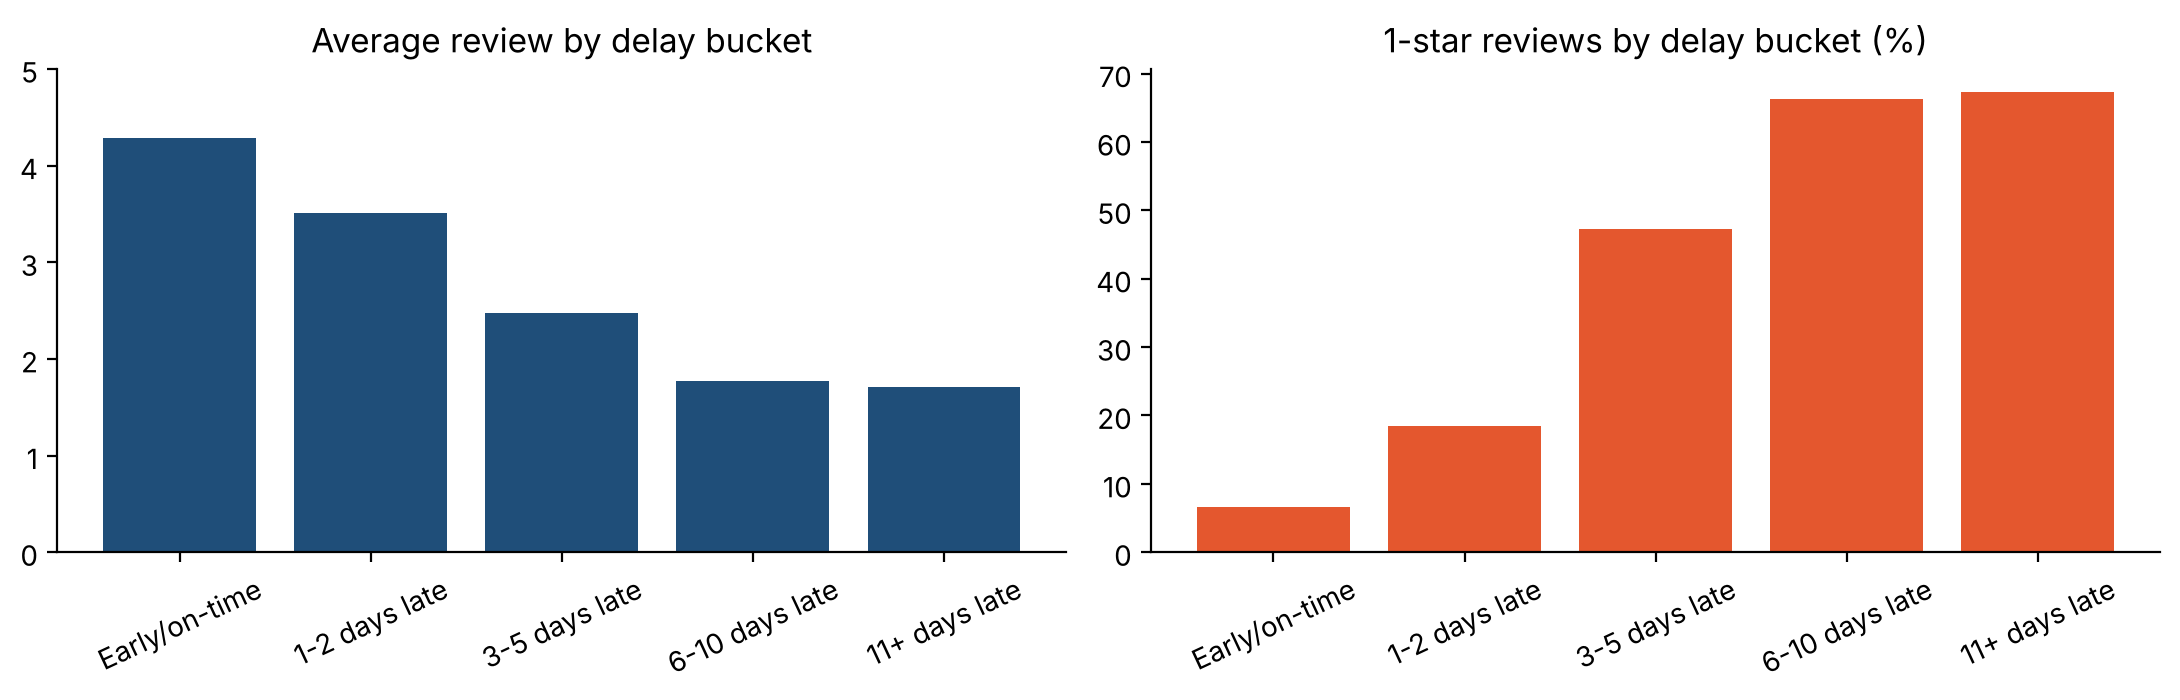

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
labels = [b.split(". ")[1] for b in delay_bucket_summary.delay_bucket]
ax[0].bar(labels, delay_bucket_summary.avg_review, color="#1F4E79")
ax[0].set_title("Average review by delay bucket"); ax[0].set_ylim(0, 5)
ax[1].bar(labels, delay_bucket_summary.pct_one_star, color="#E4572E")
ax[1].set_title("1-star reviews by delay bucket (%)")
for a in ax:
    a.tick_params(axis="x", rotation=25)
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### 4.2 Where does the delay come from? Seller or carrier?

In [18]:
stage = con.execute("""
select avg(case when is_late = 1 then seller_days end)   as seller_late,
       avg(case when is_late = 0 then seller_days end)   as seller_ontime,
       avg(case when is_late = 1 then carrier_days end)  as carrier_late,
       avg(case when is_late = 0 then carrier_days end)  as carrier_ontime
from order_facts
""").fetchdf().iloc[0]

extra_seller = stage.seller_late - stage.seller_ontime
extra_carrier = stage.carrier_late - stage.carrier_ontime
print(f"Late orders spend  +{extra_carrier:.1f} extra days with the carrier and +{extra_seller:.1f} extra days with the seller.")
print(f"Carrier share of the extra delay: {100 * extra_carrier / (extra_carrier + extra_seller):.0f}%")

Late orders spend  +19.9 extra days with the carrier and +3.0 extra days with the seller.
Carrier share of the extra delay: 87%


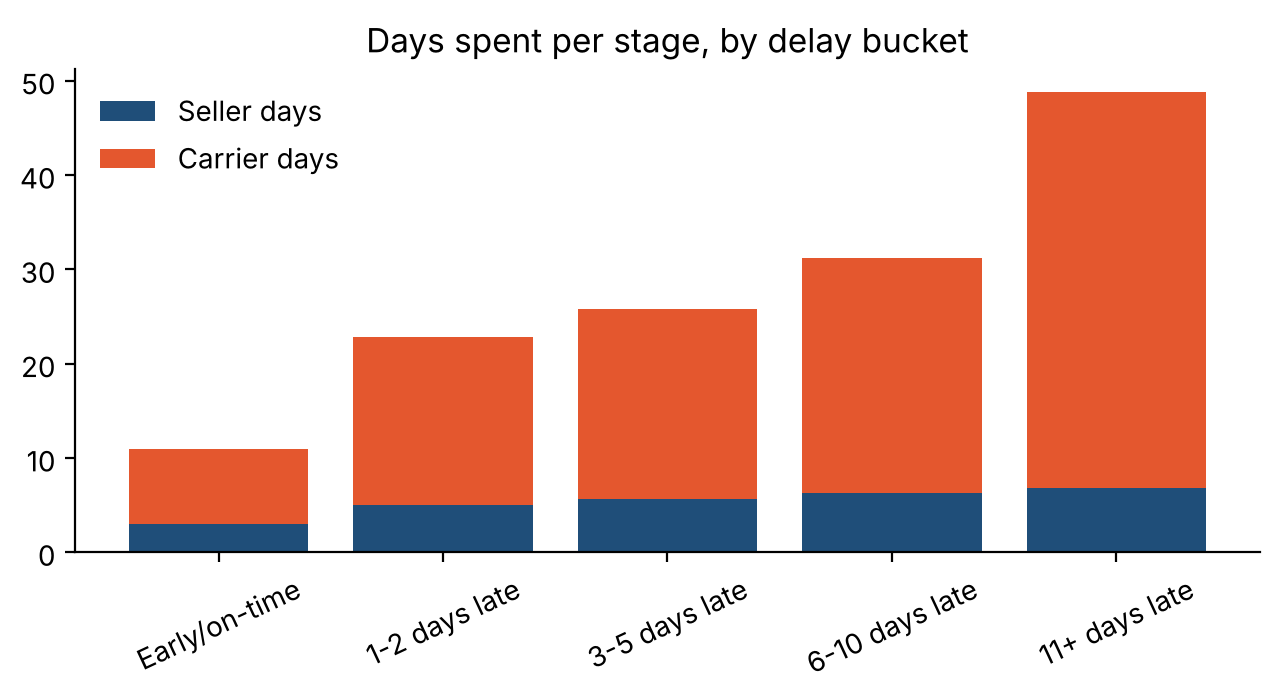

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
x = range(len(delay_bucket_summary))
ax.bar(x, delay_bucket_summary.avg_seller_days, color="#1F4E79", label="Seller days")
ax.bar(x, delay_bucket_summary.avg_carrier_days, bottom=delay_bucket_summary.avg_seller_days, color="#E4572E", label="Carrier days")
ax.set_xticks(list(x)); ax.set_xticklabels(labels, rotation=25)
ax.set_title("Days spent per stage, by delay bucket"); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### 4.3 When do spikes happen?

Months above 10% late: 2017-11 (12.4%), 2018-02 (14.1%), 2018-03 (19.0%)
Share of all late orders in those months: 48%


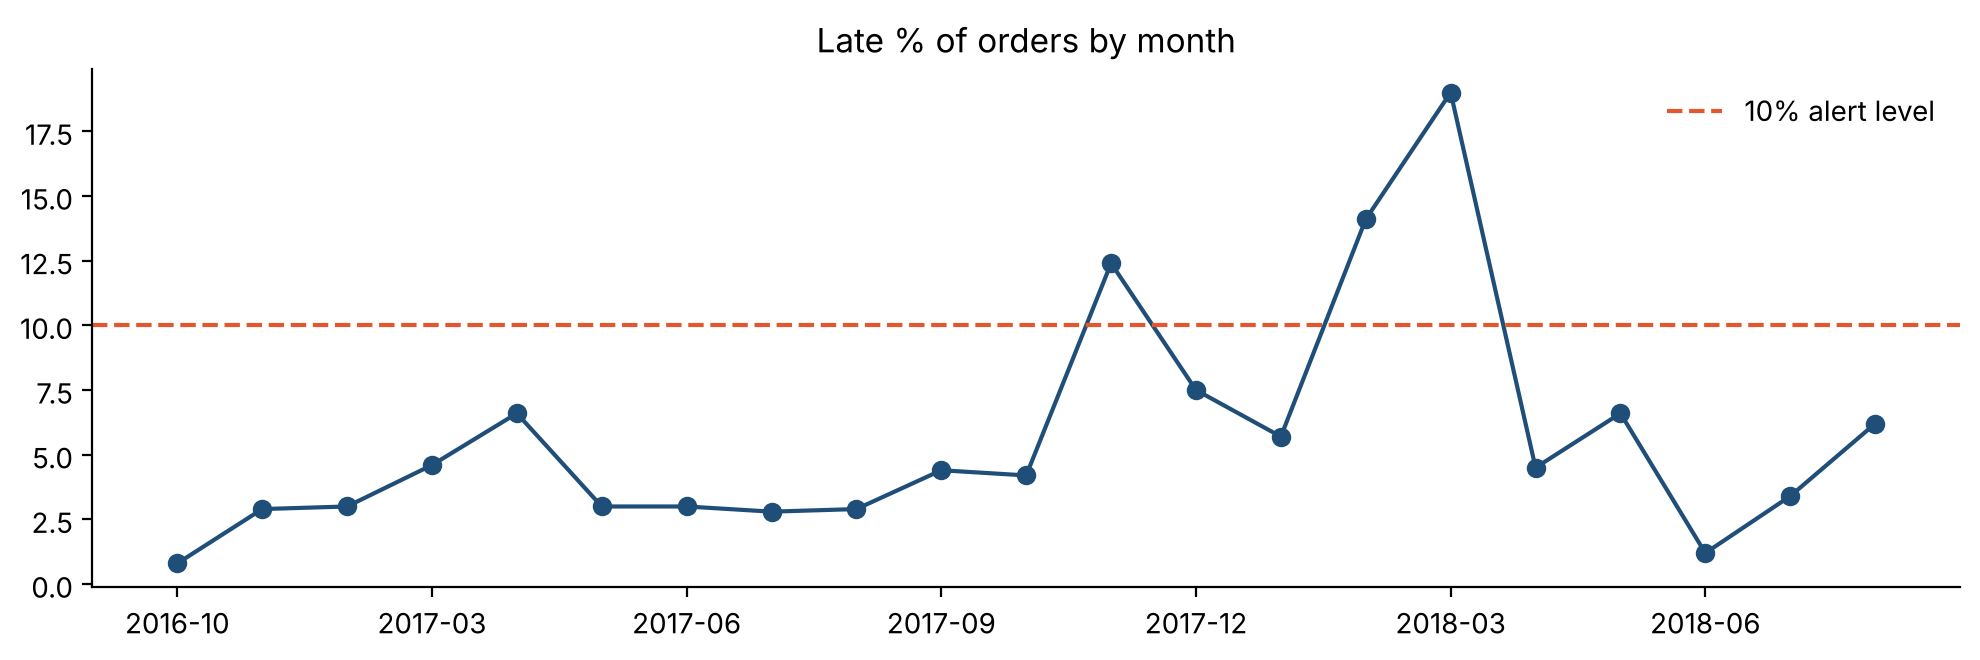

In [20]:
spikes = monthly_trend[monthly_trend.late_pct > 10]
print("Months above 10% late:", ", ".join(f"{m} ({p}%)" for m, p in zip(spikes.month, spikes.late_pct)))
print(f"Share of all late orders in those months: {100 * spikes.late_orders.sum() / monthly_trend.late_orders.sum():.0f}%")

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(monthly_trend.month, monthly_trend.late_pct, color="#1F4E79", marker="o")
ax.axhline(10, color="#E4572E", linestyle="--", label="10% alert level")
ax.set_title("Late % of orders by month"); ax.legend(frameon=False)
ax.set_xticks(range(0, len(monthly_trend), 3)); ax.set_xticklabels(monthly_trend.month[::3])
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### 4.4 Which states are the problem? (states with 100+ orders)

In [21]:
kept = state_summary[state_summary.enough_orders == 1].sort_values("late_pct", ascending=False)
print(f"States kept: {len(kept)} of {len(state_summary)}")
print(kept[["customer_state", "orders", "late_orders", "late_pct", "avg_review", "gmv"]].head(8).to_string(index=False))

sp = kept.loc[kept.customer_state == "SP", "late_pct"].iloc[0]
ne = kept[kept.customer_state.isin(["AL", "MA", "SE", "PI", "CE", "BA"])]
print(f"\nSao Paulo late rate: {sp}%.  Northeast hotspots (AL, MA, SE, PI, CE, BA): {ne.late_pct.min()}% to {ne.late_pct.max()}%  ({ne.late_pct.min() / sp:.1f}x to {ne.late_pct.max() / sp:.1f}x Sao Paulo)")

States kept: 24 of 27
customer_state  orders  late_orders  late_pct  avg_review       gmv
            AL     397         85.0      21.4        3.85   78856.0
            MA     717        125.0      17.4        3.83  117009.0
            SE     335         51.0      15.2        3.91   56574.0
            PI     476         66.0      13.9        3.99   84721.0
            CE    1279        176.0      13.8        3.94  219757.0
            BA    3256        396.0      12.2        3.93  493584.0
            RJ   12350       1495.0      12.1        3.97 1759651.0
            PA     946        106.0      11.2        3.91  174471.0

Sao Paulo late rate: 4.5%.  Northeast hotspots (AL, MA, SE, PI, CE, BA): 12.2% to 21.4%  (2.7x to 4.8x Sao Paulo)


### 4.5 Are a few bad sellers the cause?

In [22]:
# Uses the rebuilt seller table when raw data is available, otherwise the saved CSV
sellers = seller_summary if seller_summary is not None else pd.read_csv(PROCESSED / "seller_summary.csv")
top15 = sellers.sort_values("excess_late_orders", ascending=False).head(15)

kept_states = state_summary.loc[state_summary.enough_orders == 1, "customer_state"].tolist()
late_in_kept = int(state_summary.loc[state_summary.enough_orders == 1, "late_orders"].sum())
print(f"Worst 15 sellers: {top15.excess_late_orders.sum():.0f} excess late orders")
print(f"All late orders in the {len(kept_states)} kept states: {late_in_kept:,}")
print(f"Share explained by the worst 15 sellers: {100 * top15.excess_late_orders.sum() / late_in_kept:.1f}%")
print(f"Sellers analysed: {len(sellers)} (100+ orders each)")

Worst 15 sellers: 366 excess late orders
All late orders in the 24 kept states: 6,524
Share explained by the worst 15 sellers: 5.6%
Sellers analysed: 210 (100+ orders each)


### 4.6 What would fixing late deliveries be worth? (an estimate, not a forecast)

In [23]:
# What-if: late orders were reviewed like on-time orders
new_avg = kpi.review_on_time
new_one_star = kpi.one_star_on_time
print(f"Average review would move from {kpi.avg_review:.2f} to about {new_avg:.2f}")
print(f"1-star share would move from {kpi.one_star_pct:.1f}% to about {new_one_star:.1f}%")
print("This assumes late orders would be reviewed like on-time orders if delivered on time. Late orders may differ in other ways, so treat it as an upper bound.")

Average review would move from 4.16 to about 4.29
1-star share would move from 9.7% to about 6.6%
This assumes late orders would be reviewed like on-time orders if delivered on time. Late orders may differ in other ways, so treat it as an upper bound.


## 5. Limitations

- This shows **association, not proof of cause**. Late orders may also differ by product weight, distance, or carrier choice.
- **Repeat purchase is low** (about 3%) and barely changes with delay, so this dataset cannot support a strong claim about lost repeat business.
- *Expected late orders* for sellers controls for the **customer state only**, not for product type or carrier.
- **Sales value is item value**, not lost revenue.
- Small states are excluded (fewer than 100 orders) and sellers need 100+ orders, so very small groups are not ranked.
- The `came_back` rule is the closest match found to the original flag (about 99.7% of rows), not an exact reproduction.

## 6. Recommendations

1. **Fix the carrier stage first.** It causes most of the extra delay. Review carrier performance and routing, especially for long-distance states.
2. **Alert when a month passes 10% late.** A small number of months hold nearly half of all late orders.
3. **Focus on Rio de Janeiro and the Northeast.** Rio combines high late rates with high volume; Northeastern states run several times the late rate of Sao Paulo.